# Lecture 7 · Diagnostics, Remedial Measures and Nonlinear Models

Following `07_1_Diagnostics.pdf` (Kutner et al., 2005, Ch. 10) and `07_2_Remedial measures_nonlinear reg_nn.pdf` (Ch. 11 and 13).

**Data:** `tips.csv`, $n=244$, $Y$ = `tip`. **Model examined:** the week-6 selection,

$$\hat Y=b_0+b_1\,bill+b_2\,smoker+b_3\,bill\times smoker,\qquad p=4 .$$

Part 7.1 asks whether this fitted model is trustworthy and which cases drive it; part 7.2 applies a remedy to each problem found.

Case numbers below are **0-based** `pandas` row indices ("row 170" is the 171st observation), the same convention as week 4.

In [1]:
import numpy as np, pandas as pd
from scipy import stats, optimize
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess

ALPHA = 0.05
df = pd.read_csv('tips.csv')
n = len(df)
Y = df['tip'].to_numpy()
bill = df['total_bill'].to_numpy()
size_ = df['size'].to_numpy().astype(float)
smoker = (df['smoker'] == 'Yes').to_numpy().astype(float)
X = np.column_stack([np.ones(n), bill, smoker, bill * smoker])
cols = ['intercept', 'bill', 'smoker', 'bill_x_smoker']
p = X.shape[1]

XtX_inv = np.linalg.inv(X.T @ X)
b = XtX_inv @ X.T @ Y
Yhat = X @ b
e = Y - Yhat
MSE = e @ e / (n - p)
Q, _ = np.linalg.qr(X)
h = (Q**2).sum(axis=1)                         # diagonal of the hat matrix
ols = sm.OLS(Y, X).fit()
assert np.allclose(b, ols.params)
print(f'n = {n}, p = {p}, MSE = {MSE:.4f}')
print('b =', dict(zip(cols, b.round(4))))

n = 244, p = 4, MSE = 0.9575
b = {'intercept': np.float64(0.3601), 'bill': np.float64(0.1372), 'smoker': np.float64(1.2042), 'bill_x_smoker': np.float64(-0.0676)}


# Part 7.1 · Diagnostics

## Job 1 — is each predictor entering in the right form? Added-variable plots

For $X_k$: regress $Y$ on the other predictors and keep $e(Y\mid\text{others})$; regress $X_k$ on them and keep $e(X_k\mid\text{others})$;
plot the first against the second. The slope equals $b_k$ (L7.1, slide 4). A linear band means $X_k$ is fine as a linear term, a curved one suggests a
transformation, a flat one that $X_k$ adds little.

predictor        slope of plot       b_k     corr
bill                   0.13716   0.13716    0.675
smoker                 1.20420   1.20420    0.242
bill_x_smoker         -0.06757  -0.06757   -0.294


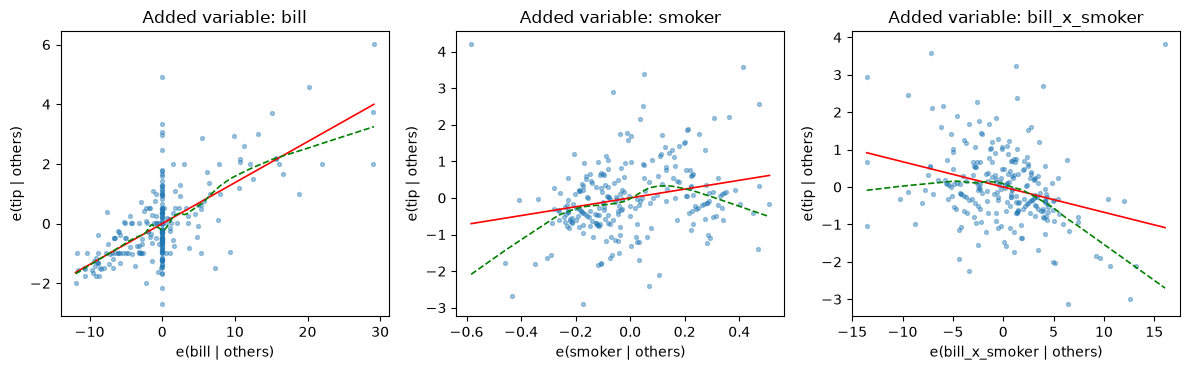

In [2]:
def resid_on(target, A):
    return target - A @ np.linalg.lstsq(A, target, rcond=None)[0]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
print(f'{"predictor":<16}{"slope of plot":>14}{"b_k":>10}{"corr":>9}')
for a, k in zip(ax, [1, 2, 3]):
    others = [j for j in range(p) if j != k]
    ey, ex = resid_on(Y, X[:, others]), resid_on(X[:, k], X[:, others])
    slope = (ex @ ey) / (ex @ ex)
    assert np.isclose(slope, b[k]), 'added-variable slope differs from b_k'
    print(f'{cols[k]:<16}{slope:>14.5f}{b[k]:>10.5f}{np.corrcoef(ex, ey)[0, 1]:>9.3f}')
    a.scatter(ex, ey, s=8, alpha=.4)
    xs = np.array([ex.min(), ex.max()]); a.plot(xs, slope * xs, 'r-', lw=1.2)
    xl = np.sort(ex); lo = lowess(ey, ex, frac=.5); a.plot(lo[:, 0], lo[:, 1], 'g--', lw=1.2)
    a.set_xlabel(f'e({cols[k]} | others)'); a.set_ylabel('e(tip | others)'); a.set_title(f'Added variable: {cols[k]}')
plt.tight_layout()
plt.savefig('images/added_variable.png')
plt.show()

## Job 2 — outlying $Y$: studentized deleted residuals

$$t_i=\frac{e_i}{\sqrt{MSE_{(i)}(1-h_{ii})}}=r_i\sqrt{\frac{n-p-1}{n-p-r_i^2}},\qquad r_i=\frac{e_i}{\sqrt{MSE(1-h_{ii})}},\quad t_i\sim t(n-p-1).$$

All $n$ cases are screened at once, so flag $|t_i|>t\!\left(1-\frac{\alpha}{2n};\,n-p-1\right)$ (Bonferroni, L7.1, slide 7). Here $\alpha=0.05$.

Bonferroni limit: t(0.99990; 239) = 3.771   (unadjusted t(0.975) = 1.970)
largest |t_i| = 5.646 (row 170);   cases above the Bonferroni limit: 1
cases with |t_i| > unadjusted 1.97: 12  (about 12 expected by chance)

  row    bill  smoker    tip    Yhat       e    h_ii    r_i    t_i   Bonf. P
  170   50.81       1  10.00    5.10    4.90  0.1123   5.31   5.65     0.000
  183   23.17       1   6.50    3.18    3.32  0.0114   3.42   3.49     0.138
  172    7.25       1   5.15    2.07    3.08  0.0313   3.20   3.26     0.308
  214   28.17       1   6.50    3.52    2.98  0.0169   3.07   3.12     0.492
  237   32.83       1   1.17    3.85   -2.68  0.0271  -2.78  -2.82     1.000
   57   26.41       0   1.50    3.98   -2.48  0.0117  -2.55  -2.58     1.000


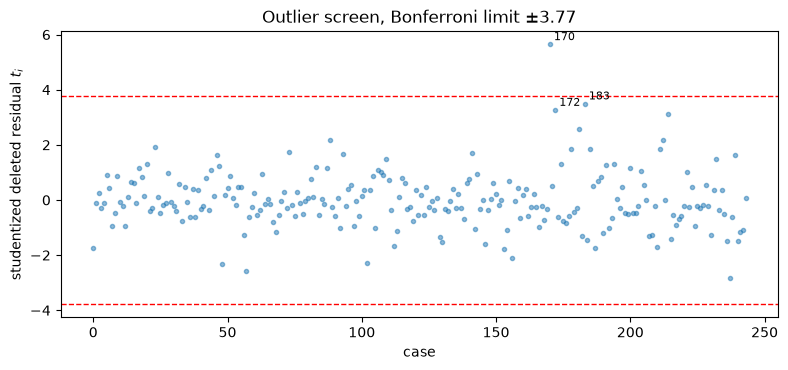

In [3]:
r_int = e / np.sqrt(MSE * (1 - h))
t_del = r_int * np.sqrt((n - p - 1) / (n - p - r_int**2))

# check one case by actually deleting it
i0 = int(np.argmax(np.abs(t_del)))
keep = np.arange(n) != i0
bi = np.linalg.lstsq(X[keep], Y[keep], rcond=None)[0]
MSE_i = ((Y[keep] - X[keep] @ bi)**2).sum() / (n - p - 1)
assert np.isclose(e[i0] / np.sqrt(MSE_i * (1 - h[i0])), t_del[i0]), 'algebraic form of t_i disagrees with explicit deletion'

infl = OLSInfluence(ols)
assert np.allclose(t_del, infl.resid_studentized_external), 'statsmodels disagrees'
tcrit_b = stats.t.ppf(1 - ALPHA / (2 * n), n - p - 1)
print(f'Bonferroni limit: t({1 - ALPHA/(2*n):.5f}; {n-p-1}) = {tcrit_b:.3f}   (unadjusted t({1-ALPHA/2:.3f}) = {stats.t.ppf(1-ALPHA/2, n-p-1):.3f})')
print(f'largest |t_i| = {np.abs(t_del).max():.3f} (row {i0});   cases above the Bonferroni limit: {(np.abs(t_del) > tcrit_b).sum()}')
print(f'cases with |t_i| > unadjusted 1.97: {(np.abs(t_del) > stats.t.ppf(1-ALPHA/2, n-p-1)).sum()}  (about {ALPHA*n:.0f} expected by chance)\n')
order = np.argsort(-np.abs(t_del))[:6]
print(f'{"row":>5}{"bill":>8}{"smoker":>8}{"tip":>7}{"Yhat":>8}{"e":>8}{"h_ii":>8}{"r_i":>7}{"t_i":>7}{"Bonf. P":>10}')
for i in order:
    P_b = min(1.0, 2 * n * stats.t.sf(abs(t_del[i]), n - p - 1))
    print(f'{i:>5}{bill[i]:>8.2f}{smoker[i]:>8.0f}{Y[i]:>7.2f}{Yhat[i]:>8.2f}{e[i]:>8.2f}{h[i]:>8.4f}{r_int[i]:>7.2f}{t_del[i]:>7.2f}{P_b:>10.3f}')

plt.figure(figsize=(8, 3.8))
plt.scatter(np.arange(n), t_del, s=9, alpha=.5)
for s_ in (tcrit_b, -tcrit_b): plt.axhline(s_, c='r', ls='--', lw=1)
for i in order[:3]: plt.annotate(str(i), (i, t_del[i]), fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.xlabel('case'); plt.ylabel('studentized deleted residual $t_i$')
plt.title(f'Outlier screen, Bonferroni limit $\\pm${tcrit_b:.2f}')
plt.tight_layout()
plt.savefig('images/deleted_residuals.png')
plt.show()

## Job 3 — outlying $X$: leverage

$h_{ii}$ is the distance of case $i$ in predictor space; $1/n\le h_{ii}\le1$, $\sum h_{ii}=p$, flag $h_{ii}>2p/n$. For a **new** case $\mathbf X_{new}$,
$h_{new,new}=\mathbf X_{new}'(\mathbf X'\mathbf X)^{-1}\mathbf X_{new}$; if it exceeds every $h_{ii}$ the point lies outside the region covered by the data
(hidden extrapolation, slide 10).

In [4]:
thr = 2 * p / n
print(f'mean h = {h.mean():.5f} (= p/n = {p/n:.5f});  2p/n = {thr:.5f};  max h = {h.max():.4f} (row {h.argmax()})')
print(f'cases with h_ii > 2p/n: {(h > thr).sum()} of {n}   (smokers {((h > thr) & (smoker == 1)).sum()}, non-smokers {((h > thr) & (smoker == 0)).sum()})\n')
top_h = np.argsort(-h)[:6]
print(f'{"row":>5}{"bill":>8}{"smoker":>8}{"tip":>7}{"h_ii":>9}{"h/(p/n)":>9}')
for i in top_h: print(f'{i:>5}{bill[i]:>8.2f}{smoker[i]:>8.0f}{Y[i]:>7.2f}{h[i]:>9.4f}{h[i]/(p/n):>9.2f}')

def h_new(xnew, Xm=X, inv=XtX_inv): return xnew @ inv @ xnew
print('\nnew cases, selected model (bill, smoker, bill x smoker):')
for bl, sm_ in [(20, 0), (50, 0), (50, 1), (5, 1)]:
    hn = h_new(np.array([1, bl, sm_, bl * sm_]))
    print(f'  bill {bl:>2}, smoker {sm_}:  h_new = {hn:.4f}   {"outside" if hn > h.max() else "inside"} the observed range of h_ii')

# week-4 model (bill, size): two predictors can each be in range while the pair is not
X4 = np.column_stack([np.ones(n), bill, size_]); inv4 = np.linalg.inv(X4.T @ X4)
h4 = np.einsum('ij,jk,ik->i', X4, inv4, X4)
hn4 = h_new(np.array([1, 50.0, 1.0]), inv=inv4)
print(f'\nweek-4 model (bill, size), new case (bill 50, size 1): h_new = {hn4:.4f}  vs  max h_ii = {h4.max():.4f}  '
      f'-> {"outside" if hn4 > h4.max() else "inside"}; bill 50 and size 1 are each inside their own range')

mean h = 0.01639 (= p/n = 0.01639);  2p/n = 0.03279;  max h = 0.1123 (row 170)
cases with h_ii > 2p/n: 17 of 244   (smokers 10, non-smokers 7)

  row    bill  smoker    tip     h_ii  h/(p/n)
  170   50.81       1  10.00   0.1123     6.85
  212   48.33       0   9.00   0.0897     5.47
   59   48.27       0   6.73   0.0894     5.45
  156   48.17       0   5.00   0.0888     5.42
  182   45.35       1   3.50   0.0788     4.80
  102   44.30       1   2.50   0.0731     4.46

new cases, selected model (bill, smoker, bill x smoker):
  bill 20, smoker 0:  h_new = 0.0067   inside the observed range of h_ii
  bill 50, smoker 0:  h_new = 0.0995   inside the observed range of h_ii
  bill 50, smoker 1:  h_new = 0.1069   inside the observed range of h_ii
  bill  5, smoker 1:  h_new = 0.0387   inside the observed range of h_ii

week-4 model (bill, size), new case (bill 50, size 1): h_new = 0.1384  vs  max h_ii = 0.0712  -> outside; bill 50 and size 1 are each inside their own range


## Job 4 — influence

$$DFFITS_i=t_i\sqrt{\tfrac{h_{ii}}{1-h_{ii}}},\qquad
D_i=\frac{e_i^2}{p\,MSE}\cdot\frac{h_{ii}}{(1-h_{ii})^2},\qquad
DFBETAS_{k(i)}=\frac{b_k-b_{k(i)}}{\sqrt{MSE_{(i)}\,c_{kk}}},\ \ c_{kk}=(\mathbf X'\mathbf X)^{-1}_{kk}.$$

Flags (small/medium samples, slides 12–13): $|DFFITS|>2\sqrt{p/n}$; $D_i$ against $F(p,n-p)$ (below the 20th percentile little influence, above the 50th
major); $|DFBETAS|>2/\sqrt n$. The lecture labels these cut-offs *small/medium data*. The textbook may instead use $1$ for small/medium samples and these values for large ones; I could not check that, so counts for both are reported and I do not call $n=244$ large or small.

DFFITS, Cook's D and DFBETAS agree with statsmodels.

|DFFITS| > 0.256: 20 cases;   |DFFITS| > 1: 1 cases
Cook D: above the 20th percentile of F(4,240) (0.412): 1 cases;  above the 50th (0.842): 1;  largest D = 0.893 (percentile 53.1)
|DFBETAS| > 0.128: intercept 7, bill 10, smoker 16, bill_x_smoker 18 cases
|DFBETAS| > 1: intercept 0, bill 0, smoker 1, bill_x_smoker 1 cases

  row   bill  smk   tip    h_ii    t_i     D_i  DFFITS  DFB_bill DFB_smoke DFB_bill_
  170  50.81    1 10.00  0.1123   5.65  0.8934   2.008     0.000    -1.115     1.397
  212  48.33    0  9.00  0.0897   2.17  0.1143   0.681     0.656     0.343    -0.447
  156  48.17    0  5.00  0.0888  -2.12  0.1080  -0.662    -0.637    -0.333     0.434
  102  44.30    1  2.50  0.0731  -2.30  0.1024  -0.646    -0.000     0.331    -0.436
  172   7.25    1  5.15  0.0313   3.26  0.0826   0.586    -0.000     0.439    -0.347
  237  32.83    1  1.17  0.0271  -2.82  0.0537  -0.470    -0.000     0.156    -0.267


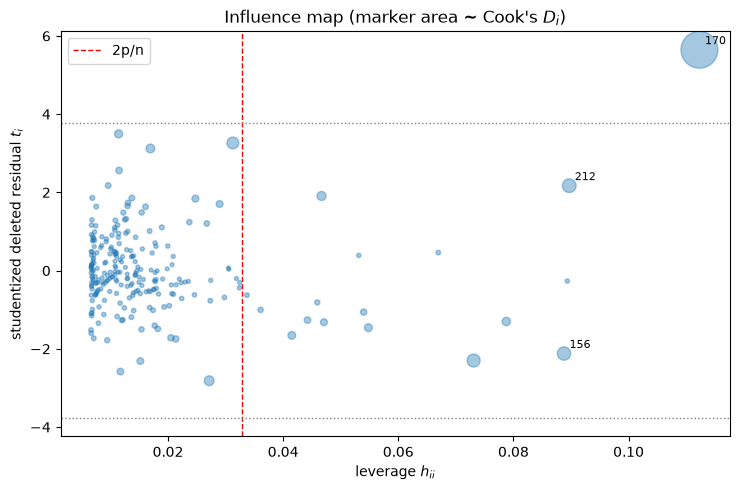

In [5]:
dffits = t_del * np.sqrt(h / (1 - h))
D = e**2 / (p * MSE) * h / (1 - h)**2
D_pct = stats.f.cdf(D, p, n - p)
MSE_del = ((n - p) * MSE - e**2 / (1 - h)) / (n - p - 1)
db = (X @ XtX_inv) * (e / (1 - h))[:, None]                    # b - b_(i), one row per case
dfbetas = db / np.sqrt(MSE_del[:, None] * np.diag(XtX_inv)[None, :])

assert np.allclose(dffits, infl.dffits[0]) and np.allclose(D, infl.cooks_distance[0]) and np.allclose(dfbetas, infl.dfbetas), 'statsmodels disagrees'
print('DFFITS, Cook\'s D and DFBETAS agree with statsmodels.\n')

c_dffits, c_dfb = 2 * np.sqrt(p / n), 2 / np.sqrt(n)
print(f'|DFFITS| > {c_dffits:.3f}: {(np.abs(dffits) > c_dffits).sum()} cases;   |DFFITS| > 1: {(np.abs(dffits) > 1).sum()} cases')
print(f'Cook D: above the 20th percentile of F({p},{n-p}) ({stats.f.ppf(.2, p, n-p):.3f}): {(D_pct > .2).sum()} cases;  '
      f'above the 50th ({stats.f.ppf(.5, p, n-p):.3f}): {(D_pct > .5).sum()};  largest D = {D.max():.3f} (percentile {100*D_pct.max():.1f})')
print(f'|DFBETAS| > {c_dfb:.3f}: ' + ', '.join(f'{cols[k]} {(np.abs(dfbetas[:, k]) > c_dfb).sum()}' for k in range(p)) + ' cases')
print('|DFBETAS| > 1: ' + ', '.join(f'{cols[k]} {(np.abs(dfbetas[:, k]) > 1).sum()}' for k in range(p)) + ' cases\n')

top_d = np.argsort(-D)[:6]
print(f'{"row":>5}{"bill":>7}{"smk":>5}{"tip":>6}{"h_ii":>8}{"t_i":>7}{"D_i":>8}{"DFFITS":>8}' + ''.join(f'{"DFB_"+c[:5]:>10}' for c in cols[1:]))
for i in top_d:
    print(f'{i:>5}{bill[i]:>7.2f}{smoker[i]:>5.0f}{Y[i]:>6.2f}{h[i]:>8.4f}{t_del[i]:>7.2f}{D[i]:>8.4f}{dffits[i]:>8.3f}' + ''.join(f'{dfbetas[i, k]:>10.3f}' for k in range(1, p)))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(h, t_del, s=700 * D / D.max() + 8, alpha=.4)
ax.axvline(thr, c='r', ls='--', lw=1, label='2p/n')
for s_ in (tcrit_b, -tcrit_b): ax.axhline(s_, c='gray', ls=':', lw=1)
for i in top_d[:3]: ax.annotate(str(i), (h[i], t_del[i]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('leverage $h_{ii}$'); ax.set_ylabel('studentized deleted residual $t_i$')
ax.set_title("Influence map (marker area ~ Cook's $D_i$)"); ax.legend()
plt.tight_layout()
plt.savefig('images/influence_map.png')
plt.show()

In [6]:
# sensitivity: with and without the most influential cases (report both, L7.1 slide 19)
def refit(drop):
    keep = np.setdiff1d(np.arange(n), drop)
    bb = np.linalg.lstsq(X[keep], Y[keep], rcond=None)[0]
    return bb, bb[1], bb[1] + bb[3]

print(f'{"":<24}{"b0":>8}{"b1 bill":>9}{"b2 smoker":>11}{"b3":>9}{"slope non-smk":>15}{"slope smk":>11}')
for lab, drop in [('all cases', []), (f'drop row {top_d[0]}', top_d[:1]), (f'drop rows {list(map(int, top_d[:3]))}', top_d[:3])]:
    bb, s0, s1 = refit(drop)
    print(f'{lab:<24}{bb[0]:>8.4f}{bb[1]:>9.4f}{bb[2]:>11.4f}{bb[3]:>9.4f}{s0:>15.4f}{s1:>11.4f}')
print(f'\nrow {top_d[0]}: smoker = {smoker[top_d[0]]:.0f}, bill = {bill[top_d[0]]:.2f}, tip = {Y[top_d[0]]:.2f}')

                              b0  b1 bill  b2 smoker       b3  slope non-smk  slope smk
all cases                 0.3601   0.1372     1.2042  -0.0676         0.1372     0.0696
drop row 170              0.3601   0.1372     1.5320  -0.0862         0.1372     0.0509
drop rows [170, 212, 156]  0.3634   0.1370     1.5287  -0.0860         0.1370     0.0509

row 170: smoker = 1, bill = 50.81, tip = 10.00


### Refined multicollinearity: VIF

$VIF_k=1/(1-R_k^2)$; above 10 signals serious multicollinearity (slide 18). An interaction is built from its main effects, so it overlaps them; centering `bill` first (week 5) lowers the overlap. Only `bill` is centered: `smoker` stays 0/1 and the interaction is centered bill $\\times$ smoker.

In [7]:
def vifs(Xm): return [variance_inflation_factor(Xm, j) for j in range(1, Xm.shape[1])]
v_raw = vifs(X)
bill_c = bill - bill.mean()
Xc = np.column_stack([np.ones(n), bill_c, smoker, bill_c * smoker])
v_c = vifs(Xc)
# manual check of one VIF
others = [0, 2, 3]
r2k = 1 - (resid_on(X[:, 1], X[:, others])**2).sum() / ((X[:, 1] - X[:, 1].mean())**2).sum()
assert np.isclose(1 / (1 - r2k), v_raw[0])
print(f'{"":<16}{"raw bill":>10}{"centered bill":>15}')
for nm_, a_, c_ in zip(cols[1:], v_raw, v_c): print(f'{nm_:<16}{a_:>10.2f}{c_:>15.2f}')
print(f'\nmean VIF: raw {np.mean(v_raw):.2f}, centered {np.mean(v_c):.2f}')
smoker_c = smoker - smoker.mean()
v_cc = vifs(np.column_stack([np.ones(n), bill_c, smoker_c, bill_c * smoker_c]))
print(f'(centering both bill and smoker instead: VIF {np.round(v_cc, 2)})')
fc = sm.OLS(Y, Xc).fit()
print(f'fitted values identical after centering: {np.allclose(fc.fittedvalues, Yhat)};  '
      f'smoker coefficient changes from {b[2]:.3f} (at bill = 0) to {fc.params[2]:.3f} (at the mean bill {bill.mean():.2f})')

                  raw bill  centered bill
bill                  1.88           1.88
smoker                5.86           1.01
bill_x_smoker         7.08           1.88

mean VIF: raw 4.94, centered 1.59
(centering both bill and smoker instead: VIF [1.04 1.01 1.03])
fitted values identical after centering: True;  smoker coefficient changes from 1.204 (at bill = 0) to -0.133 (at the mean bill 19.79)


---

# Part 7.2 · Remedial measures and nonlinear models

A tool for each broken assumption (L7.2, slide 4): unequal variance $\to$ weighted least squares; multicollinearity $\to$ ridge; influential cases
$\to$ robust regression; unknown curved shape $\to$ lowess or trees; no formula for precision $\to$ bootstrap. Chapter 13 changes the model form itself.
The slides are concept-first, so the settings below (variance function, ridge $k$, weight functions, bootstrap size) are my choices and are stated.

## Weighted least squares (unequal variances)

The residuals fan out with the fitted value (week 3). Weight each case by $w_i=1/\hat\sigma_i^2$. The standard deviation function is estimated by regressing
$|e_i|$ on $\hat Y_i$, using the fitted $\hat s_i$ in $w_i=1/\hat s_i^2$, and iterating twice.

                    OLS b   OLS se   HC3 se    WLS b   WLS se
intercept          0.3601   0.2021   0.1994   0.3794   0.1708
bill               0.1372   0.0097   0.0118   0.1361   0.0108
smoker             1.2042   0.3123   0.4662   1.0693   0.2682
bill_x_smoker     -0.0676   0.0142   0.0255  -0.0605   0.0155

slope of the bill: non-smokers OLS 0.1372 / WLS 0.1361;  smokers OLS 0.0696 / WLS 0.0756

sd of residuals by fitted-value third (low / middle / high):
  OLS residuals           0.662 / 0.829 / 1.308
  WLS weighted residuals  1.337 / 1.232 / 1.363
Breusch-Pagan: OLS X2 = 102.6 (P = 4.2e-22);  WLS (weighted residuals) X2 = 28.3 (P = 3.1e-06)


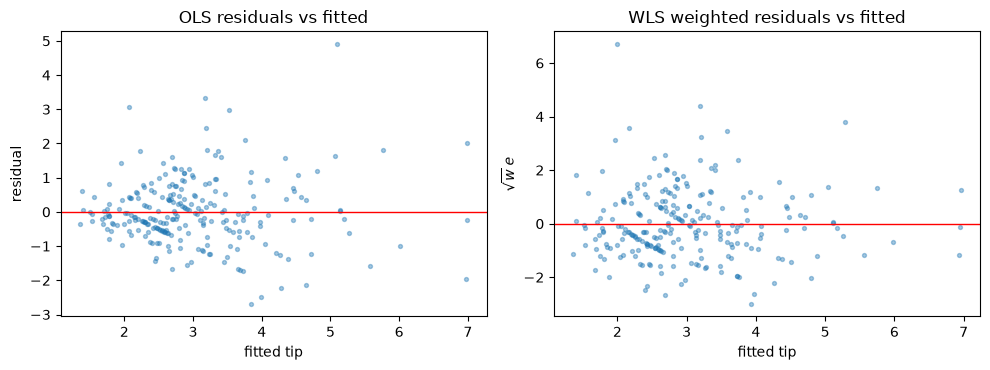

In [8]:
w = np.ones(n)
bw = b.copy()
for it in range(2):
    ew = Y - X @ bw
    A = np.column_stack([np.ones(n), X @ bw])
    sd_hat = A @ np.linalg.lstsq(A, np.abs(ew), rcond=None)[0]
    assert (sd_hat > 0).all(), 'estimated standard deviation not positive'
    w = 1 / sd_hat**2
    bw = np.linalg.solve(X.T @ (w[:, None] * X), X.T @ (w * Y))
wls = sm.WLS(Y, X, weights=w).fit()
assert np.allclose(wls.params, bw)
hc3 = sm.OLS(Y, X).fit(cov_type='HC3')
print(f'{"":<16}{"OLS b":>9}{"OLS se":>9}{"HC3 se":>9}{"WLS b":>9}{"WLS se":>9}')
for k_, nm_ in enumerate(cols):
    print(f'{nm_:<16}{b[k_]:>9.4f}{ols.bse[k_]:>9.4f}{hc3.bse[k_]:>9.4f}{wls.params[k_]:>9.4f}{wls.bse[k_]:>9.4f}')
print(f'\nslope of the bill: non-smokers OLS {b[1]:.4f} / WLS {wls.params[1]:.4f};  smokers OLS {b[1]+b[3]:.4f} / WLS {wls.params[1]+wls.params[3]:.4f}')

fit_terc = np.digitize(Yhat, np.quantile(Yhat, [1/3, 2/3]))
e_w = (Y - X @ wls.params) * np.sqrt(w)
print('\nsd of residuals by fitted-value third (low / middle / high):')
print('  OLS residuals          ', ' / '.join(f'{e[fit_terc == g].std(ddof=1):.3f}' for g in range(3)))
print('  WLS weighted residuals ', ' / '.join(f'{e_w[fit_terc == g].std(ddof=1):.3f}' for g in range(3)))

def bp(res, Xm):
    w2 = res**2; bb = np.linalg.lstsq(Xm, w2, rcond=None)[0]
    chi2 = ((Xm @ bb - w2.mean())**2).sum() / 2 / ((res @ res) / len(res))**2
    return chi2, stats.chi2.sf(chi2, Xm.shape[1] - 1)
print(f'Breusch-Pagan: OLS X2 = {bp(e, X)[0]:.1f} (P = {bp(e, X)[1]:.2g});  WLS (weighted residuals) X2 = {bp(e_w, X)[0]:.1f} (P = {bp(e_w, X)[1]:.2g})')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
ax[0].scatter(Yhat, e, s=8, alpha=.4); ax[0].axhline(0, c='r', lw=1)
ax[0].set_title('OLS residuals vs fitted'); ax[0].set_xlabel('fitted tip'); ax[0].set_ylabel('residual')
ax[1].scatter(X @ wls.params, e_w, s=8, alpha=.4); ax[1].axhline(0, c='r', lw=1)
ax[1].set_title('WLS weighted residuals vs fitted'); ax[1].set_xlabel('fitted tip'); ax[1].set_ylabel('$\\sqrt{w}\\,e$')
plt.tight_layout()
plt.savefig('images/wls_residuals.png')
plt.show()

## Robust regression (outliers and influential cases)

M-estimation down-weights cases with large residuals so no single point governs the fit. Two weight functions from `statsmodels`: Huber and Tukey's biweight
(default tuning constants).

In [9]:
rlm_h = sm.RLM(Y, X, M=sm.robust.norms.HuberT()).fit()
rlm_t = sm.RLM(Y, X, M=sm.robust.norms.TukeyBiweight()).fit()
b_drop3 = refit(top_d[:3])[0]
print(f'{"":<28}{"b0":>8}{"b1 bill":>9}{"b2 smoker":>11}{"b3":>9}{"slope smk":>11}')
for lab, bb in [('OLS', b), ('OLS without the 3 top-D rows', b_drop3), ('Huber', rlm_h.params), ('Tukey biweight', rlm_t.params)]:
    print(f'{lab:<28}{bb[0]:>8.4f}{bb[1]:>9.4f}{bb[2]:>11.4f}{bb[3]:>9.4f}{bb[1] + bb[3]:>11.4f}')

wt = rlm_t.weights
print(f'\nTukey weights: {(wt < 1e-6).sum()} cases get weight 0, {(wt < 0.5).sum()} get weight below 0.5')
low = np.argsort(wt)[:5]
print('lowest-weight cases:', [(int(i), round(float(wt[i]), 3)) for i in low])
print('highest Cook\'s D cases:', [int(i) for i in top_d[:5]])

                                  b0  b1 bill  b2 smoker       b3  slope smk
OLS                           0.3601   0.1372     1.2042  -0.0676     0.0696
OLS without the 3 top-D rows  0.3634   0.1370     1.5287  -0.0860     0.0509
Huber                         0.3752   0.1366     1.2063  -0.0761     0.0605
Tukey biweight                0.3556   0.1377     1.2891  -0.0835     0.0542

Tukey weights: 2 cases get weight 0, 13 get weight below 0.5
lowest-weight cases: [(170, 0.0), (183, 0.0), (214, 0.003), (172, 0.03), (181, 0.129)]
highest Cook's D cases: [170, 212, 156, 102, 172]


## Ridge regression (severe multicollinearity)

Ridge needs collinear predictors, which the selected model hardly has (VIFs above). Use the week-5 model with `bill`, `size` and `per_person` $=$ `bill`/`size`
(VIF 17.3, 10.4, 11.4). On the correlation-transformed variables

$$\mathbf b^R(k)=(\mathbf r_{XX}+k\mathbf I)^{-1}\mathbf r_{YX},\qquad k=0\ \text{is ordinary least squares.}$$

Choose the smallest $k$ at which the coefficients settle (slide 6); here, the smallest on the grid with every ridge $VIF<10$.

VIF at k = 0: [17.3 10.4 11.4]
       k   b*_bill   b*_size     b*_pp  max VIF      R2
   0.000     0.806    -0.024    -0.179    17.28  0.4707
   0.005     0.737     0.026    -0.125    12.38  0.4704
   0.010     0.685     0.064    -0.084     9.26  0.4698
   0.020     0.613     0.115    -0.029     5.75  0.4685
   0.049     0.513     0.181     0.045     2.37  0.4656
   0.100     0.442     0.219     0.091     1.02  0.4623
   0.492     0.313     0.217     0.123     0.32  0.4387
   1.000     0.249     0.180     0.109     0.19  0.4000

smallest k with every VIF < 10: k = 0.0100


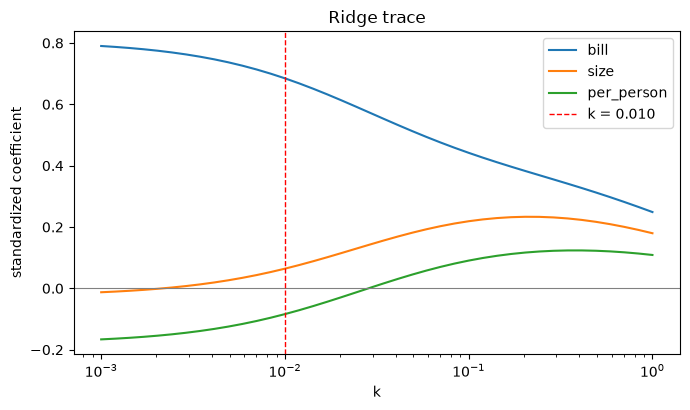

In [10]:
pp = bill / size_
Xr = np.column_stack([bill, size_, pp])
rn = ['bill', 'size', 'per_person']
Ys = (Y - Y.mean()) / Y.std(ddof=1) / np.sqrt(n - 1)
Xs = (Xr - Xr.mean(0)) / Xr.std(0, ddof=1) / np.sqrt(n - 1)
rXX, rYX = Xs.T @ Xs, Xs.T @ Ys

ks = np.concatenate([[0], np.logspace(-3, 0, 40)])
trace = np.array([np.linalg.solve(rXX + k_ * np.eye(3), rYX) for k_ in ks])
def ridge_vif(k_):
    Ainv = np.linalg.inv(rXX + k_ * np.eye(3)); return np.diag(Ainv @ rXX @ Ainv)
vif_k = np.array([ridge_vif(k_) for k_ in ks])
R2_k = 1 - ((Ys[:, None] - Xs @ trace.T)**2).sum(axis=0)
k_star = ks[np.argmax(vif_k.max(axis=1) < 10)]
print(f'VIF at k = 0: {np.round(vif_k[0], 1)}')
print(f'{"k":>8}{"b*_bill":>10}{"b*_size":>10}{"b*_pp":>10}{"max VIF":>9}{"R2":>8}')
for k_ in [0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1.0]:
    i = np.argmin(np.abs(ks - k_))
    print(f'{ks[i]:>8.3f}{trace[i, 0]:>10.3f}{trace[i, 1]:>10.3f}{trace[i, 2]:>10.3f}{vif_k[i].max():>9.2f}{R2_k[i]:>8.4f}')
print(f'\nsmallest k with every VIF < 10: k = {k_star:.4f}')

plt.figure(figsize=(7, 4.2))
for j, nm_ in enumerate(rn): plt.plot(ks[1:], trace[1:, j], label=nm_)
plt.xscale('log'); plt.axhline(0, c='gray', lw=.8); plt.axvline(k_star, c='r', ls='--', lw=1, label=f'k = {k_star:.3f}')
plt.xlabel('k'); plt.ylabel('standardized coefficient'); plt.legend(); plt.title('Ridge trace')
plt.tight_layout()
plt.savefig('images/ridge_trace.png')
plt.show()

## Nonparametric regression: lowess and a regression tree

No functional form is assumed. Lowess joins many small local regressions (fraction $0.5$ of the data in each window); a tree splits $X$ into regions and predicts the mean in each.

SSE (in sample):  straight line 252.79    lowess 260.99    depth-2 tree (4 leaves) 263.42
tree split points on bill: [13.81, 20.45, 32.9]


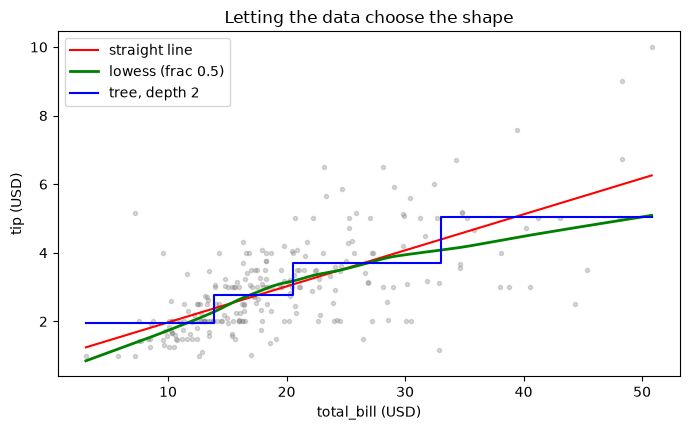

In [11]:
lo = lowess(Y, bill, frac=0.5)
lo_fit = np.interp(bill, lo[:, 0], lo[:, 1])
b_lin = np.polyfit(bill, Y, 1)
sse_lin, sse_lo = ((Y - np.polyval(b_lin, bill))**2).sum(), ((Y - lo_fit)**2).sum()

def tree(x, y, depth, min_leaf=15):
    if depth == 0 or len(y) < 2 * min_leaf: return ('leaf', y.mean())
    best = None
    for s_ in np.unique(x)[min_leaf:-min_leaf]:
        l, r_ = y[x <= s_], y[x > s_]
        if len(l) < min_leaf or len(r_) < min_leaf: continue
        sse = ((l - l.mean())**2).sum() + ((r_ - r_.mean())**2).sum()
        if best is None or sse < best[0]: best = (sse, s_)
    if best is None: return ('leaf', y.mean())
    s_ = best[1]
    return ('split', s_, tree(x[x <= s_], y[x <= s_], depth - 1), tree(x[x > s_], y[x > s_], depth - 1))
def predict(t_, x):
    if t_[0] == 'leaf': return np.full(len(x), t_[1])
    out = np.empty(len(x)); m = x <= t_[1]
    out[m] = predict(t_[2], x[m]); out[~m] = predict(t_[3], x[~m]); return out
def splits(t_, acc=None):
    acc = [] if acc is None else acc
    if t_[0] == 'split': acc.append(round(float(t_[1]), 2)); splits(t_[2], acc); splits(t_[3], acc)
    return acc

tr2 = tree(bill, Y, 2)
sse_tr = ((Y - predict(tr2, bill))**2).sum()
print(f'SSE (in sample):  straight line {sse_lin:.2f}    lowess {sse_lo:.2f}    depth-2 tree (4 leaves) {sse_tr:.2f}')
print(f'tree split points on bill: {sorted(splits(tr2))}')

# lowess against the line by thirds of the bill
grid = np.linspace(bill.min(), bill.max(), 200)
plt.figure(figsize=(7, 4.4))
plt.scatter(bill, Y, s=9, alpha=.3, color='gray')
plt.plot(grid, np.polyval(b_lin, grid), 'r-', label='straight line')
plt.plot(lo[:, 0], lo[:, 1], 'g-', lw=2, label='lowess (frac 0.5)')
plt.step(grid, predict(tr2, grid), 'b-', where='post', label='tree, depth 2')
plt.xlabel('total_bill (USD)'); plt.ylabel('tip (USD)'); plt.legend()
plt.title('Letting the data choose the shape')
plt.tight_layout()
plt.savefig('images/lowess_tree.png')
plt.show()

## The bootstrap: precision without formulas

Resample the $n$ cases with replacement, refit, repeat; the spread of the estimates is a standard error and their percentiles a confidence interval. Here $B=2000$ resamples of cases (pairs bootstrap).

In [12]:
rng = np.random.default_rng(7)
B = 2000
boot = np.empty((B, p))
for i in range(B):
    idx = rng.integers(0, n, n)
    boot[i] = np.linalg.lstsq(X[idx], Y[idx], rcond=None)[0]
slope_s = boot[:, 1] + boot[:, 3]

print(f'{"":<16}{"b":>9}{"OLS se":>9}{"HC3 se":>9}{"boot se":>9}{"boot 95% CI":>22}')
for k_, nm_ in enumerate(cols):
    lo_, hi_ = np.percentile(boot[:, k_], [2.5, 97.5])
    print(f'{nm_:<16}{b[k_]:>9.4f}{ols.bse[k_]:>9.4f}{hc3.bse[k_]:>9.4f}{boot[:, k_].std(ddof=1):>9.4f}   [{lo_:7.4f}, {hi_:7.4f}]')
lo_, hi_ = np.percentile(slope_s, [2.5, 97.5])
print(f'\nslope of the bill for smokers (b1 + b3): {b[1] + b[3]:.4f}, bootstrap se {slope_s.std(ddof=1):.4f}, 95% CI [{lo_:.4f}, {hi_:.4f}]')
lo_, hi_ = np.percentile(boot[:, 3], [2.5, 97.5])
print(f'interaction b3: bootstrap 95% CI [{lo_:.4f}, {hi_:.4f}]  -> {"excludes" if hi_ < 0 or lo_ > 0 else "includes"} 0')

                        b   OLS se   HC3 se  boot se           boot 95% CI
intercept          0.3601   0.2021   0.1994   0.1901   [-0.0124,  0.7368]
bill               0.1372   0.0097   0.0118   0.0112   [ 0.1155,  0.1591]
smoker             1.2042   0.3123   0.4662   0.4295   [ 0.3447,  2.0247]
bill_x_smoker     -0.0676   0.0142   0.0255   0.0232   [-0.1118, -0.0204]

slope of the bill for smokers (b1 + b3): 0.0696, bootstrap se 0.0200, 95% CI [0.0346, 0.1127]
interaction b3: bootstrap 95% CI [-0.1118, -0.0204]  -> excludes 0


## Nonlinear regression and a small neural network

**Nonlinear least squares:** parameters enter inside a function; the search is iterative and inference is approximate (slides 10–11). A power curve
$Y=a\,X^{c}$ has meaningful parameters: $c<1$ means tips grow less than proportionally with the bill.

**Neural network:** one hidden layer of $m$ tanh units on the standardized predictors, fitted by minimising squared error plus a small ridge penalty
(L-BFGS, best of 3 random starts). No interpretable coefficients, so it is judged only by prediction on held-out cases (slide 13).

In [13]:
# nonlinear least squares: power curve
f_pow = lambda x, a, c: a * x**c
popt, pcov = optimize.curve_fit(f_pow, bill, Y, p0=[0.5, 0.8])
se_ = np.sqrt(np.diag(pcov))
sse_pow = ((Y - f_pow(bill, *popt))**2).sum()
print(f'power curve  tip = a * bill^c:  a = {popt[0]:.4f} (se {se_[0]:.4f}),  c = {popt[1]:.4f} (se {se_[1]:.4f})')
print(f'  approximate 95% CI for c: [{popt[1] - 1.97*se_[1]:.3f}, {popt[1] + 1.97*se_[1]:.3f}]   (c = 1 would mean proportional)')
print(f'SSE: straight line with intercept {sse_lin:.2f}   power curve (2 parameters) {sse_pow:.2f}   week-6 model (4 parameters) {e @ e:.2f}')

# neural network vs the selected linear model on repeated 50/50 splits
def feat(idx_, mu=None, sd=None):
    F = np.column_stack([bill, smoker])[idx_]
    return F, F.mean(0) if mu is None else mu, F.std(0) if sd is None else sd

def nn_unpack(theta, m, d):
    W1 = theta[:d * m].reshape(d, m); b1 = theta[d * m:d * m + m]
    W2 = theta[d * m + m:d * m + 2 * m]; b2 = theta[-1]
    return W1, b1, W2, b2
def nn_pred(theta, F, m):
    W1, b1, W2, b2 = nn_unpack(theta, m, F.shape[1]); return np.tanh(F @ W1 + b1) @ W2 + b2
def nn_fit(F, y, m, lam, rs):
    d = F.shape[1]; best = None
    for _ in range(3):
        th0 = rs.normal(0, .5, d * m + 2 * m + 1)
        loss = lambda th: ((nn_pred(th, F, m) - y)**2).mean() + lam * (th[:d * m]**2).sum()
        r_ = optimize.minimize(loss, th0, method='L-BFGS-B', options={'maxiter': 300})
        if best is None or r_.fun < best.fun: best = r_
    return best.x

def split_mspr(tr, va, m, rs):
    Ft, mu, sd = feat(tr); Fv, _, _ = feat(va, mu, sd)
    th = nn_fit((Ft - mu) / sd, Y[tr], m, 1e-3, rs)
    nn_tr = ((Y[tr] - nn_pred(th, (Ft - mu) / sd, m))**2).mean()
    nn_va = ((Y[va] - nn_pred(th, (Fv - mu) / sd, m))**2).mean()
    bl = np.linalg.lstsq(X[tr], Y[tr], rcond=None)[0]
    return nn_tr, nn_va, ((Y[va] - X[va] @ bl)**2).mean(), ((Y[tr] - X[tr] @ bl)**2).mean()

rs = np.random.default_rng(11)
R = 100
out = np.empty((R, 2, 2))                  # [split, model (linear, nn), (train mse, validation mse)]
for r_ in range(R):
    pm = rs.permutation(n); tr_, va_ = pm[:n // 2], pm[n // 2:]
    a_tr, a_va, l_va, l_tr = split_mspr(tr_, va_, 4, rs)
    out[r_] = [[l_tr, l_va], [a_tr, a_va]]
print(f'\n{R} random 50/50 splits (inputs: bill and smoker; the network must find the interaction itself):')
print(f'{"model":<28}{"train MSE":>11}{"MSPR":>9}{"sd":>8}')
for j, nm_ in enumerate(['linear, selected (4 par.)', 'network, 4 hidden units']):
    print(f'{nm_:<28}{out[:, j, 0].mean():>11.4f}{out[:, j, 1].mean():>9.4f}{out[:, j, 1].std(ddof=1):>8.4f}')
print(f'network has the smaller MSPR in {(out[:, 1, 1] < out[:, 0, 1]).mean():.0%} of splits;  mean train MSE {out[:, 1, 0].mean():.3f} vs MSPR {out[:, 1, 1].mean():.3f}')

power curve  tip = a * bill^c:  a = 0.3674 (se 0.0576),  c = 0.7095 (se 0.0492)
  approximate 95% CI for c: [0.613, 0.806]   (c = 1 would mean proportional)
SSE: straight line with intercept 252.79   power curve (2 parameters) 253.02   week-6 model (4 parameters) 229.81



100 random 50/50 splits (inputs: bill and smoker; the network must find the interaction itself):
model                         train MSE     MSPR      sd
linear, selected (4 par.)        0.8895   1.0594  0.1702
network, 4 hidden units          0.6669   1.4206  0.8884
network has the smaller MSPR in 17% of splits;  mean train MSE 0.667 vs MSPR 1.421
